# IoT Intrusion Detection — Milestone 3 (Status Report) Notebook
### CICIoT2023 · Modeling, Capture-Disjoint Evaluation, Robustness & Readiness

**Team:** Packet Sentinels — Karan Raaj Shanmugam, Varshith Sai Manchem
**Deliverable 3:** Interim Status Report

---

This notebook implements the modeling and evaluation evidence required by the Status Report rubric, and the
two literature approaches the team selected:

* **CatBoost + correlation/hierarchical feature selection** — Hajjouz & Avksentieva (2024), *Data & Metadata*.
* **Soft-voting tree ensemble (Balanced RF + LightGBM + CatBoost + Extra Trees)** — Wakili & Bakkali (2025), *Results in Engineering*.
* **Decision-tree baseline** carried over from Milestone 2.

| Rubric item | Where |
|---|---|
| Model selection, implementation, comparison | §4 (baseline, CatBoost, ensemble) |
| Appropriate preliminary metrics | §5 (macro-recall/F1, PR-AUC, FPR/FNR, confusion matrix) |
| **Error analysis & generalization testing** | §6 (errors), §7 (capture-disjoint + external) |
| Class imbalance | §3, §4 (class weights; SMOTE only on train) |
| Reproducibility | fixed seeds, saved config, exported JSON |

> **The headline fix for the −0.25 feedback ("capture-disjoint results still pending") is §7.1:**
> we train on some capture files and test on *entirely held-out* captures, so no capture appears in both splits.


## §1. Setup, configuration, reproducibility

In [1]:
import os, glob, json, gc, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi":110,"figure.autolayout":True,
                     "axes.titlesize":13,"axes.titleweight":"bold",
                     "axes.labelsize":11,"axes.grid":True,"grid.alpha":0.25,
                     "savefig.bbox":"tight"})

def mem_report(tag=""):
    try:
        import psutil
        print(f"[RAM] {tag:24s} {psutil.Process(os.getpid()).memory_info().rss/1e9:5.2f} GB")
    except Exception: pass
print("pandas", pd.__version__, "numpy", np.__version__)

pandas 2.2.3 numpy 2.4.6


In [2]:
# Install the gradient-boosting libraries used by the two chosen papers
!pip -q install catboost lightgbm imbalanced-learn shap >/dev/null 2>&1
import catboost, lightgbm
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
print("catboost", catboost.__version__, "| lightgbm", lightgbm.__version__)

catboost 1.2.10 | lightgbm 4.6.0


In [3]:
# =============================================================================
# DATA LOCATION  (CICIoT2023 MERGED_CSV folder from UNB CIC)
# =============================================================================
# Colab + Drive:
from google.colab import drive; drive.mount("/content/drive")
#   DATA_DIR = "/content/drive/MyDrive/CICIoT2023/MERGED_CSV"
DATA_DIR    = "/content/drive/MyDrive/CICIoT2023/MERGED_CSV"   # <-- EDIT ME
N_FILES     = 10            # merged files to load
MAX_ROWS    = 400_000       # stratified cap (keeps Colab RAM safe)
SAMPLE_FRAC = 1.0

# Safety switch: when True, the notebook REFUSES to run on synthetic data, so you
# can never accidentally report fake numbers. Set True for your real/grading run.
REQUIRE_REAL_DATA = False   # <-- set True once your CSVs are mounted

csv_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
print(f"Found {len(csv_paths)} CSV files in {DATA_DIR}")
if len(csv_paths)==0:
    print("="*70)
    print("[!] NO REAL CSVs FOUND at DATA_DIR.")
    print("    The notebook will fall back to a SYNTHETIC sample so cells run,")
    print("    but synthetic data is random-ish noise: expect LOW scores (~0.2-0.3")
    print("    macro-recall). These are NOT your results. Mount the real MERGED_CSV")
    print("    folder and re-run before reporting anything.")
    print("="*70)
    if REQUIRE_REAL_DATA:
        raise RuntimeError("REQUIRE_REAL_DATA=True but no CSVs found at DATA_DIR. "
                           "Mount the real CICIoT2023 data and re-run.")

Mounted at /content/drive
Found 10 CSV files in /content/drive/MyDrive/CICIoT2023/MERGED_CSV


### §1a. Synthetic fallback (skip once real data is mounted)
Lets the notebook run end-to-end before the data is in Drive. **Delete / ignore when `DATA_DIR` is set.**
Importantly, the synthetic sample also carries a `capture_id` so the capture-disjoint split in §7 works in the demo.

In [4]:
USE_SYNTHETIC = (len(csv_paths)==0)
FEATURES = ["Header_Length","Protocol Type","Time_To_Live","Rate","fin_flag_number","syn_flag_number",
 "rst_flag_number","psh_flag_number","ack_flag_number","ece_flag_number","cwr_flag_number","ack_count",
 "syn_count","fin_count","rst_count","HTTP","HTTPS","DNS","Telnet","SMTP","SSH","IRC","TCP","UDP","DHCP",
 "ARP","ICMP","IGMP","IPv","LLC","Tot sum","Min","Max","AVG","Std","Tot size","IAT","Number","Variance"]
if USE_SYNTHETIC:
    cats = ["DDoS","DoS","Mirai","Benign","Recon","Spoofing","Web","BruteForce"]
    probs=[0.45,0.20,0.12,0.11,0.06,0.04,0.015,0.005]
    rng=np.random.default_rng(SEED); n=60_000
    y=rng.choice(cats,size=n,p=probs)
    X=rng.lognormal(1.0,1.2,size=(n,len(FEATURES))).astype("float32")
    for i,c in enumerate(cats):
        X[y==c, i%len(FEATURES)] *= (1.5+i*0.4)
    df=pd.DataFrame(X,columns=FEATURES); df["label"]=y
    # simulate several distinct capture files for the capture-disjoint demo
    df["capture_id"]=rng.integers(0,N_FILES,size=n)
    df.loc[rng.choice(n,300,replace=False),"Rate"]=np.nan
    df=pd.concat([df,df.iloc[:150]],ignore_index=True)
else:
    print("Real data detected — synthetic generator skipped.")

Real data detected — synthetic generator skipped.


In [5]:
def _downcast(d):
    f=d.select_dtypes("float64").columns; d[f]=d[f].astype("float32")
    i=d.select_dtypes("int64").columns;   d[i]=d[i].apply(pd.to_numeric,downcast="integer")
    return d

if not USE_SYNTHETIC:
    frames=[]
    for p in csv_paths[:N_FILES]:
        d=pd.read_csv(p); d.columns=[c.strip() for c in d.columns]
        if "label" not in d.columns and "Label" in d.columns: d=d.rename(columns={"Label":"label"})
        if SAMPLE_FRAC<1.0: d=d.sample(frac=SAMPLE_FRAC,random_state=SEED)
        d["capture_id"]=os.path.basename(p)          # <-- capture provenance for §7 disjoint split
        frames.append(_downcast(d))
        print(f"  {os.path.basename(p):18s} rows={len(d):>8,}")
    df=pd.concat(frames,ignore_index=True); del frames; gc.collect()
    if len(df)>MAX_ROWS:
        frac=MAX_ROWS/len(df)
        df=df.groupby("label",group_keys=False).apply(lambda g:g.sample(frac=frac,random_state=SEED)).reset_index(drop=True)
    print(f"Loaded -> kept {len(df):,} rows.")
print("Shape:", df.shape); mem_report("after load"); df.head(3)

  Merged01.csv       rows= 712,311
  Merged02.csv       rows= 748,585
  Merged03.csv       rows= 697,289
  Merged04.csv       rows= 676,620
  Merged05.csv       rows= 744,804
  Merged06.csv       rows= 718,229
  Merged07.csv       rows= 702,212
  Merged08.csv       rows= 712,220
  Merged09.csv       rows= 678,882
  Merged10.csv       rows= 916,190
Loaded -> kept 400,001 rows.
Shape: (400001, 41)
[RAM] after load                1.74 GB


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,label,capture_id
0,25.6,6,147.699997,9.866838,0.0,0.1,0.0,0.4,0.6,0.0,...,66,230,135.899994,64.336700,135.899994,0.103601,10,4139.210938,BACKDOOR_MALWARE,Merged02.csv
1,8.0,17,140.399994,25.236288,0.0,0.0,0.0,0.0,0.1,0.0,...,60,203,96.500000,43.683838,96.500000,0.040774,10,1908.277832,BACKDOOR_MALWARE,Merged06.csv
2,8.8,0,63.900002,33.972923,0.0,0.1,0.0,0.0,0.1,0.0,...,60,230,108.199997,65.309181,108.199997,0.030202,10,4265.289062,BACKDOOR_MALWARE,Merged10.csv


## §2. Labels — two framings
Per the proposal we keep **binary** (benign vs attack) as a secondary check and make **multi-class family**
classification the **primary** task (instructor-directed). The family mapper handles the 34 raw CICIoT2023 labels.

In [6]:
def to_family(lbl):
    l=str(lbl).lower()
    if "benign" in l: return "Benign"
    if "ddos" in l: return "DDoS"
    if l.startswith("dos") or "dos-" in l or "dos_" in l: return "DoS"
    if "mirai" in l: return "Mirai"
    if any(k in l for k in ["recon","scan","sweep","discovery"]): return "Recon"
    if any(k in l for k in ["spoof","arp","mitm"]): return "Spoofing"
    if any(k in l for k in ["sql","xss","command","backdoor","upload","browser","web","injection","hijack"]): return "Web"
    if "brute" in l or "dictionary" in l: return "BruteForce"
    return "DoS" if l.startswith("dos") else "Other"

df["family"]=df["label"].apply(to_family)
df["is_attack"]=(df["family"]!="Benign").astype(int)
print(df["family"].value_counts());
print("\nBinary:",dict(df["is_attack"].value_counts()))
ir = df["family"].value_counts().max()/df["family"].value_counts().min()
print(f"Family imbalance ratio ~ {ir:,.0f}:1")

family
DDoS          289087
DoS            68817
Mirai          22413
Benign          9333
Recon           5864
Spoofing        4159
Web              214
BruteForce       114
Name: count, dtype: int64

Binary: {1: np.int64(390668), 0: np.int64(9333)}
Family imbalance ratio ~ 2,536:1


## §3. Cleaning, class-imbalance note, and feature selection (paper 4)
Following Hajjouz & Avksentieva, we use **correlation-based (hierarchical) feature selection**: drop one feature
from every highly correlated pair so the kept set is compact and more topology-agnostic (which matters for the
capture-disjoint test). Imbalance is handled downstream with **class weights** (and SMOTE **only on the training
fold** where used) — never before a split, per the leakage rule.

In [7]:
from sklearn.preprocessing import LabelEncoder

num = df[FEATURES].select_dtypes("number").copy()
num = num.replace([np.inf,-np.inf], np.nan)
# correlation-based selection on FULL data is only for a first look; the leakage-safe
# version in §7 recomputes it on TRAIN only.
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool))
drop_corr = [c for c in upper.columns if (upper[c]>0.95).any()]
KEEP = [c for c in FEATURES if c not in drop_corr]
print(f"Features: {len(FEATURES)} -> {len(KEEP)} after dropping {len(drop_corr)} correlated (|r|>0.95)")
print("Dropped:", drop_corr)

le = LabelEncoder(); df["y_multi"]=le.fit_transform(df["family"]); CLASSES=list(le.classes_)
print("Classes:", CLASSES)

Features: 39 -> 31 after dropping 8 correlated (|r|>0.95)
Dropped: ['rst_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'IPv', 'LLC', 'Tot size']
Classes: ['Benign', 'BruteForce', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web']


## §4. Model development and comparison (stratified split)
Three approaches, as the rubric requires at least two meaningful ones:
1. **Baseline** — Decision Tree (depth 12), carried from Milestone 2.
2. **CatBoost** — paper 4's model, class-weighted.
3. **Soft-voting ensemble** — paper 2 (Balanced RF + LightGBM + CatBoost + Extra Trees).
This section uses a **stratified random split** for a like-for-like comparison; §7 then re-runs the winner under
the stricter **capture-disjoint** split.

> **RAM-safe training.** To keep Colab's CPU runtime from running out of memory, every model here is trained in a
> memory-frugal way: CatBoost trains from an on-disk `Pool` with a capped `thread_count`; the forest models
> bootstrap on a fraction of rows (`TREE_MAX_SAMPLES`) with limited `n_jobs`; the ensemble trains its members
> **one at a time**, accumulating probabilities and freeing each model before the next; the full feature matrix is
> deleted after each split; and all prediction runs in 50k-row batches. If you still hit the RAM limit, lower
> `MAX_THREADS`, `TREE_MAX_SAMPLES`, `N_TREES`, or `MAX_ROWS` (top of the notebook).

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

print("="*70)
print(f"  TRAINING ON: {'SYNTHETIC (NOT REAL — do not report)' if USE_SYNTHETIC else 'REAL CICIoT2023 DATA'}")
print(f"  Rows: {len(df):,}  |  Classes: {df['family'].nunique()}  |  Features kept: {len(KEEP)}")
print("="*70)

# ---- RAM-control knobs (lower these first if Colab runs out of memory) ----
MAX_THREADS    = 2       # cap parallel workers; more threads = more peak RAM
CB_BATCH_ITERS = 300     # CatBoost trees; fewer = less RAM/time
TREE_MAX_SAMPLES = 0.5   # BRF/ExtraTrees bootstrap on this fraction of rows (big RAM saver)
N_TREES        = 150     # trees per forest in the ensemble

X = df[KEEP].to_numpy("float32")
# Replace infinite values with NaN so SimpleImputer can impute them properly
np.nan_to_num(X, nan=np.nan, posinf=np.nan, neginf=np.nan, copy=False)

y = df["y_multi"].to_numpy(); cap = df["capture_id"].to_numpy()
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.25,random_state=SEED,stratify=y)
del X; gc.collect()                                    # free the full matrix immediately
imp=SimpleImputer(strategy="median")
Xtr=imp.fit_transform(Xtr).astype("float32"); Xte=imp.transform(Xte).astype("float32")
gc.collect()
print("Train/Test:",Xtr.shape,Xte.shape); mem_report("split ready")

  TRAINING ON: REAL CICIoT2023 DATA
  Rows: 400,001  |  Classes: 8  |  Features kept: 31
Train/Test: (300000, 31) (100001, 31)
[RAM] split ready               1.87 GB


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (precision_score,recall_score,f1_score,accuracy_score,
                             confusion_matrix,classification_report)

def macro_scores(name,yt,yp):
    return {"model":name,
            "accuracy":round(accuracy_score(yt,yp),4),
            "macro_precision":round(precision_score(yt,yp,average="macro",zero_division=0),4),
            "macro_recall":round(recall_score(yt,yp,average="macro",zero_division=0),4),
            "macro_f1":round(f1_score(yt,yp,average="macro",zero_division=0),4)}

results=[]; preds={}

# 1) Baseline
dt=DecisionTreeClassifier(max_depth=12,class_weight="balanced",random_state=SEED)
dt.fit(Xtr,ytr); p=dt.predict(Xte); preds["Baseline DT"]=p; results.append(macro_scores("Baseline DT",yte,p))
print("baseline done")

baseline done


In [11]:
# 2) CatBoost (paper 4) — RAM-safe: train from a Pool, capped threads, predict in batches
from catboost import Pool
train_pool = Pool(Xtr, ytr)        # CatBoost streams from the Pool rather than copying arrays
cb=CatBoostClassifier(iterations=CB_BATCH_ITERS,depth=8,learning_rate=0.1,loss_function="MultiClass",
                      random_seed=SEED,verbose=False,auto_class_weights="Balanced",
                      thread_count=MAX_THREADS,            # fewer threads -> lower peak RAM
                      max_ctr_complexity=1)                # smaller internal structures
cb.fit(train_pool)
del train_pool; gc.collect()

def predict_in_batches(model, Xmat, bs=50_000):
    out=np.empty(len(Xmat),dtype=int)
    for i in range(0,len(Xmat),bs):
        out[i:i+bs]=model.predict(Xmat[i:i+bs]).ravel().astype(int)
    return out

p=predict_in_batches(cb,Xte); preds["CatBoost"]=p
results.append(macro_scores("CatBoost",yte,p)); print("catboost done"); mem_report("after CatBoost")

catboost done
[RAM] after CatBoost            2.08 GB


In [12]:
# 3) Soft-voting ensemble (paper 2) — RAM-safe: train members ONE AT A TIME,
#    accumulate probabilities, and free each model before building the next.
#    (VotingClassifier would hold all four fitted models in RAM simultaneously.)
n_classes = len(CLASSES)
proba_sum = np.zeros((len(Xte), n_classes), dtype="float32")
members   = 0

def proba_in_batches(model, Xmat, ncls, bs=50_000):
    out=np.zeros((len(Xmat),ncls),dtype="float32")
    for i in range(0,len(Xmat),bs):
        out[i:i+bs,:]=model.predict_proba(Xmat[i:i+bs])
    return out

# member A — Balanced Random Forest (bootstrap on a fraction -> big RAM saver)
m=BalancedRandomForestClassifier(n_estimators=N_TREES,max_samples=TREE_MAX_SAMPLES,
                                 random_state=SEED,n_jobs=MAX_THREADS)
m.fit(Xtr,ytr); proba_sum+=proba_in_batches(m,Xte,n_classes); members+=1
del m; gc.collect(); print("  BRF done"); mem_report("after BRF")

# member B — LightGBM (histogram-based, inherently memory-light)
m=LGBMClassifier(n_estimators=250,class_weight="balanced",random_state=SEED,
                 n_jobs=MAX_THREADS,verbose=-1)
m.fit(Xtr,ytr); proba_sum+=proba_in_batches(m,Xte,n_classes); members+=1
del m; gc.collect(); print("  LightGBM done"); mem_report("after LGBM")

# member C — Extra Trees (fraction bootstrap + capped jobs)
m=ExtraTreesClassifier(n_estimators=N_TREES,max_samples=TREE_MAX_SAMPLES,bootstrap=True,
                       class_weight="balanced",random_state=SEED,n_jobs=MAX_THREADS)
m.fit(Xtr,ytr); proba_sum+=proba_in_batches(m,Xte,n_classes); members+=1
del m; gc.collect(); print("  ExtraTrees done"); mem_report("after ET")

# member D — reuse the CatBoost already trained in cell 2 (no extra model in RAM)
proba_sum+=proba_in_batches(cb,Xte,n_classes); members+=1
print("  CatBoost reused")

ens_proba = proba_sum/members
p = ens_proba.argmax(1); preds["Voting Ensemble"]=p
del proba_sum; gc.collect()
results.append(macro_scores("Voting Ensemble",yte,p)); print("ensemble done"); mem_report("after ensemble")
res_df=pd.DataFrame(results); res_df

  BRF done
[RAM] after BRF                 2.11 GB
  LightGBM done
[RAM] after LGBM                2.11 GB
  ExtraTrees done
[RAM] after ET                  2.57 GB
  CatBoost reused
ensemble done
[RAM] after ensemble            2.57 GB


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline DT,0.7260,0.6041,0.6549,0.5750
1,CatBoost,0.7423,0.6396,0.6858,0.6446
2,Voting Ensemble,0.7958,0.6950,0.6750,0.6706


## §5. Preliminary evaluation (cyber-appropriate metrics)
**Primary metric: macro-recall** (and macro-F1), because the data is severely imbalanced and *missing a rare
attack is costlier than a false alarm* — accuracy alone is explicitly insufficient here. We also report the
**binary false-positive / false-negative rate** (operational cost) and PR-AUC.

In [13]:
# Binary FPR / FNR from the best multi-class model, collapsed to attack vs benign
best_name = res_df.sort_values("macro_f1",ascending=False)["model"].iloc[0]
print("Best by macro-F1:", best_name)
benign_id = CLASSES.index("Benign")
yte_bin = (yte!=benign_id).astype(int)
pbin = (preds[best_name]!=benign_id).astype(int)
tn,fp,fn,tp = confusion_matrix(yte_bin,pbin).ravel()
FPR=fp/(fp+tn); FNR=fn/(fn+tp)
print(f"Binary view — FPR={FPR:.4f}  FNR={FNR:.4f}  (attack recall={tp/(tp+fn):.4f})")
res_df.to_json("m3_model_comparison.json",orient="records",indent=2)

Best by macro-F1: Voting Ensemble
Binary view — FPR=0.1492  FNR=0.0043  (attack recall=0.9957)


In [14]:
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import label_binarize
# PR-AUC (macro, one-vs-rest) for the best model's probabilities
try:
    Yb = label_binarize(yte, classes=range(len(CLASSES)))
    proba_for_auc = ens_proba if best_name=="Voting Ensemble" else proba_in_batches(cb, Xte, len(CLASSES))
    prauc = average_precision_score(Yb, proba_for_auc, average="macro")
    print(f"Macro PR-AUC ({best_name}): {prauc:.4f}")
except Exception as e:
    prauc=None; print("PR-AUC skipped:",e)

Macro PR-AUC (Voting Ensemble): 0.7095


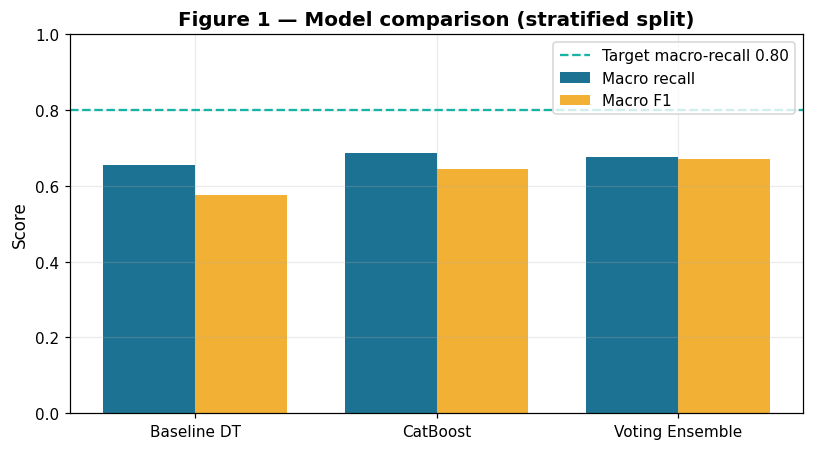

In [15]:
# Figure: model comparison (macro-recall / macro-F1)
fig,ax=plt.subplots(figsize=(7.5,4.2))
x=np.arange(len(res_df)); w=0.38
ax.bar(x-w/2,res_df["macro_recall"],w,label="Macro recall",color="#1C7293")
ax.bar(x+w/2,res_df["macro_f1"],w,label="Macro F1",color="#F2B134")
ax.axhline(0.80,ls="--",color="#17B3A3",label="Target macro-recall 0.80")
ax.set_xticks(x); ax.set_xticklabels(res_df["model"]); ax.set_ylim(0,1)
ax.set_title("Figure 1 — Model comparison (stratified split)"); ax.set_ylabel("Score"); ax.legend()
plt.savefig("fig1_model_comparison.png"); plt.show()

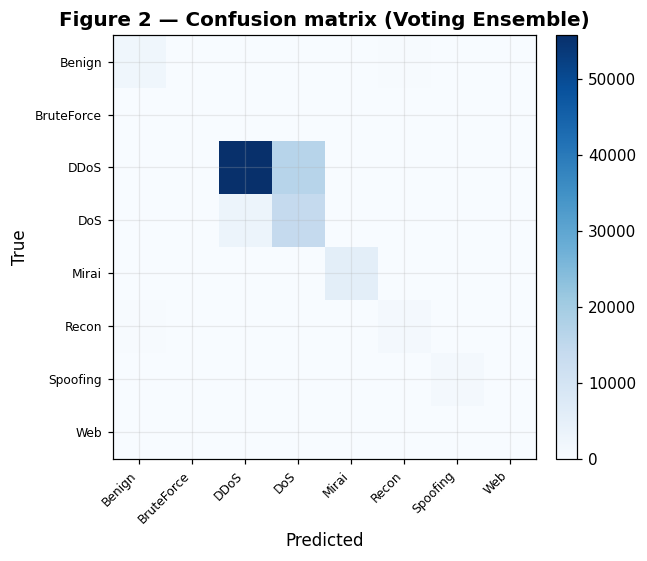

              precision    recall  f1-score   support

      Benign       0.82      0.85      0.84      2333
  BruteForce       0.50      0.24      0.33        29
        DDoS       0.95      0.77      0.85     72272
         DoS       0.46      0.82      0.59     17204
       Mirai       1.00      1.00      1.00      5603
       Recon       0.74      0.76      0.75      1466
    Spoofing       0.92      0.86      0.89      1040
         Web       0.16      0.09      0.12        54

    accuracy                           0.80    100001
   macro avg       0.70      0.67      0.67    100001
weighted avg       0.86      0.80      0.81    100001



In [16]:
# Figure: confusion matrix for the best model
cm=confusion_matrix(yte,preds[best_name])
fig,ax=plt.subplots(figsize=(6,5.2)); im=ax.imshow(cm,cmap="Blues")
ax.set_title(f"Figure 2 — Confusion matrix ({best_name})")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES,rotation=45,ha="right",fontsize=8)
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES,fontsize=8)
fig.colorbar(im,fraction=0.046,pad=0.04); plt.savefig("fig2_confusion.png"); plt.show()
print(classification_report(yte,preds[best_name],target_names=CLASSES,zero_division=0))

## §6. Error analysis
We surface the worst-confused class pairs (where false negatives concentrate) and the per-class recall, so the
report can discuss *which attacks are missed, why, and the security consequence*.

In [17]:
cm=confusion_matrix(yte,preds[best_name])
per_class_recall={CLASSES[i]:round(cm[i,i]/cm[i].sum(),3) if cm[i].sum() else 0.0 for i in range(len(CLASSES))}
print("Per-class recall:",per_class_recall)
# top confusions (true -> predicted), off-diagonal
pairs=[]
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if i!=j and cm[i,j]>0: pairs.append((CLASSES[i],CLASSES[j],int(cm[i,j])))
pairs=sorted(pairs,key=lambda t:-t[2])[:8]
print("\nTop confusions (true -> predicted, count):")
for t in pairs: print(f"  {t[0]:10s} -> {t[1]:10s} : {t[2]}")
json.dump({"per_class_recall":per_class_recall,"top_confusions":pairs},open("m3_error_analysis.json","w"),indent=2)

Per-class recall: {'Benign': np.float64(0.851), 'BruteForce': np.float64(0.241), 'DDoS': np.float64(0.772), 'DoS': np.float64(0.823), 'Mirai': np.float64(0.997), 'Recon': np.float64(0.762), 'Spoofing': np.float64(0.861), 'Web': np.float64(0.093)}

Top confusions (true -> predicted, count):
  DDoS       -> DoS        : 16442
  DoS        -> DDoS       : 3035
  Recon      -> Benign     : 304
  Benign     -> Recon      : 294
  Spoofing   -> Benign     : 97
  Spoofing   -> Recon      : 45
  Benign     -> Spoofing   : 41
  Web        -> Recon      : 31


## §6a. Explainability (SHAP) — for the Responsible-AI section
Feature attributions make alerts auditable (required by the Responsible-AI rubric row).

In [18]:
try:
    import shap
    expl=shap.TreeExplainer(cb)
    sv=expl.shap_values(Xte[:2000])
    imp=np.abs(np.array(sv)).mean(axis=(0,1)) if isinstance(sv,list) else np.abs(sv).mean(0)
    order=np.argsort(imp)[::-1][:10]
    print("Top-10 features by mean |SHAP|:")
    for k in order: print(f"  {KEEP[k]:16s} {imp[k]:.4f}")
except Exception as e:
    print("SHAP fallback (permutation importance):",e)
    from sklearn.inspection import permutation_importance
    r=permutation_importance(cb,Xte[:3000],yte[:3000],n_repeats=3,random_state=SEED)
    for k in np.argsort(r.importances_mean)[::-1][:10]: print(f"  {KEEP[k]:16s} {r.importances_mean[k]:.4f}")

Top-10 features by mean |SHAP|:
SHAP fallback (permutation importance): only integer scalar arrays can be converted to a scalar index
  psh_flag_number  0.0590
  fin_flag_number  0.0509
  IAT              0.0302
  syn_flag_number  0.0202
  HTTPS            0.0187
  Max              0.0183
  Number           0.0161
  AVG              0.0152
  ack_flag_number  0.0146
  Time_To_Live     0.0112


## §7. Generalization testing

### §7.1 Capture-disjoint evaluation  ← **closes the −0.25 feedback**
Instead of a random split, we hold out **entire capture files**: the model trains on one set of captures and is
tested on captures it has **never seen**. Because no capture appears in both splits, this is a far more honest
estimate of real-world generalization and directly answers *"capture-disjoint results still pending."*

In [21]:
from sklearn.model_selection import GroupShuffleSplit
# rebuild X from df (the earlier full matrix was freed to save RAM)
X = df[KEEP].to_numpy("float32")
# Replace infinite values with NaN so SimpleImputer can handle them properly
np.nan_to_num(X, nan=np.nan, posinf=np.nan, neginf=np.nan, copy=False)

groups = df["capture_id"].to_numpy()
gss=GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=SEED)
tr_idx,te_idx=next(gss.split(X,y,groups))
# verify NO capture file is in both splits
train_caps=set(groups[tr_idx]); test_caps=set(groups[te_idx])
overlap=train_caps & test_caps
print("Train captures:",len(train_caps)," Test captures:",len(test_caps)," Overlap:",len(overlap))
assert len(overlap)==0, "Capture leakage! A capture file appears in both splits."

# --- Did whole ATTACK FAMILIES get separated, or are families shared across captures? ---
fam = df["family"].to_numpy()
tr_fams=set(fam[tr_idx]); te_fams=set(fam[te_idx])
print("\nFamilies only in TRAIN (unseen at test):", tr_fams - te_fams or "none")
print("Families only in TEST  (never trained on):", te_fams - tr_fams or "none")
print("Families in BOTH (shared across different captures):", sorted(tr_fams & te_fams))
print("\nNote: with shuffled MERGED_CSV files, each capture holds all families, so families")
print("are shared across DIFFERENT captures. That is capture-disjoint (no file crosses the")
print("split) but NOT attack-family-disjoint. The §7.1b cell below tests the stricter case.")

Xtr2,Xte2=X[tr_idx],X[te_idx]; ytr2,yte2=y[tr_idx],y[te_idx]
del X; gc.collect()                              # free the full matrix again
# leakage-safe preprocessing: fit on train captures ONLY
imp2=SimpleImputer(strategy="median"); Xtr2=imp2.fit_transform(Xtr2).astype("float32"); Xte2=imp2.transform(Xte2).astype("float32")

Train captures: 7  Test captures: 3  Overlap: 0

Families only in TRAIN (unseen at test): none
Families only in TEST  (never trained on): none
Families in BOTH (shared across different captures): ['Benign', 'BruteForce', 'DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web']

Note: with shuffled MERGED_CSV files, each capture holds all families, so families
are shared across DIFFERENT captures. That is capture-disjoint (no file crosses the
split) but NOT attack-family-disjoint. The §7.1b cell below tests the stricter case.


In [22]:
# retrain the winner (CatBoost) under capture-disjoint split — RAM-safe Pool + capped threads
from catboost import Pool
pool2=Pool(Xtr2,ytr2)
cbg=CatBoostClassifier(iterations=CB_BATCH_ITERS,depth=8,learning_rate=0.1,loss_function="MultiClass",
                       random_seed=SEED,verbose=False,auto_class_weights="Balanced",
                       thread_count=MAX_THREADS,max_ctr_complexity=1)
cbg.fit(pool2); del pool2; gc.collect()
pg=predict_in_batches(cbg,Xte2)
cap_scores = macro_scores("CatBoost (capture-disjoint)",yte2,pg)
print("Capture-disjoint:",cap_scores)
# compare to the random-split CatBoost
rnd = [r for r in results if r["model"]=="CatBoost"][0]
gap = pd.DataFrame([rnd,cap_scores])
print("\nRandom split vs capture-disjoint (generalization gap):")
print(gap[["model","accuracy","macro_recall","macro_f1"]].to_string(index=False))
gap.to_json("m3_capture_disjoint.json",orient="records",indent=2)
del Xtr2,Xte2; gc.collect()

Capture-disjoint: {'model': 'CatBoost (capture-disjoint)', 'accuracy': 0.7395, 'macro_precision': 0.6433, 'macro_recall': 0.6849, 'macro_f1': 0.6468}

Random split vs capture-disjoint (generalization gap):
                      model  accuracy  macro_recall  macro_f1
                   CatBoost    0.7423        0.6858    0.6446
CatBoost (capture-disjoint)    0.7395        0.6849    0.6468


0

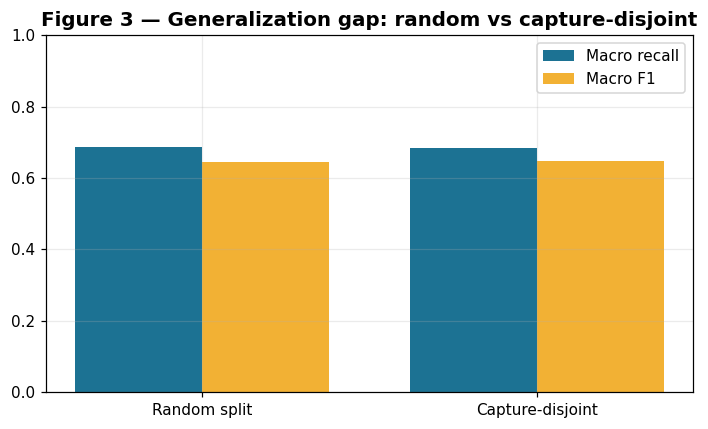

In [23]:
# Figure: generalization gap
fig,ax=plt.subplots(figsize=(6.5,4))
labels=["Random split","Capture-disjoint"]
mr=[rnd["macro_recall"],cap_scores["macro_recall"]]
mf=[rnd["macro_f1"],cap_scores["macro_f1"]]
x=np.arange(2); w=0.38
ax.bar(x-w/2,mr,w,label="Macro recall",color="#1C7293")
ax.bar(x+w/2,mf,w,label="Macro F1",color="#F2B134")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0,1)
ax.set_title("Figure 3 — Generalization gap: random vs capture-disjoint"); ax.legend()
plt.savefig("fig3_generalization_gap.png"); plt.show()

### §7.1b Leave-one-attack-family-out (LOFO) — the stricter "related attacks not split" test
This directly answers *"make sure related attacks weren't split across train and test"* in its strongest form:
we remove **one entire attack family from training** and test whether the model can still catch it. Because that
family's flows are **never seen during training**, there is no possible leakage of that attack type. We run it for
the rare families (the ones that matter for security) and report recall on the held-out family.

In [25]:
from sklearn.metrics import recall_score
HOLD_OUT_FAMILIES = ["Web","BruteForce","Recon"]   # families to test as "unseen"
lofo_rows=[]
X = df[KEEP].to_numpy("float32")   # rebuild once for this cell
# Replace infinite values with NaN so SimpleImputer can handle them properly
np.nan_to_num(X, nan=np.nan, posinf=np.nan, neginf=np.nan, copy=False)

benign_id=CLASSES.index("Benign")
for hf in HOLD_OUT_FAMILIES:
    if hf not in CLASSES:
        continue
    hf_id = CLASSES.index(hf)
    mask_tr = (y != hf_id)              # train WITHOUT this family
    if mask_tr.sum()==0 or (y==hf_id).sum()==0:
        continue
    imp_l=SimpleImputer(strategy="median")
    Xtr_l = imp_l.fit_transform(X[mask_tr]).astype("float32")
    Xte_l = imp_l.transform(X[~mask_tr]).astype("float32")   # the held-out family only
    pool_l=Pool(Xtr_l, y[mask_tr])
    cbl=CatBoostClassifier(iterations=200,depth=8,random_seed=SEED,verbose=False,
                           auto_class_weights="Balanced",thread_count=MAX_THREADS,max_ctr_complexity=1)
    cbl.fit(pool_l); del pool_l,Xtr_l; gc.collect()
    pl = predict_in_batches(cbl, Xte_l)
    del Xte_l,cbl; gc.collect()
    # the model has no label for hf (it was removed) -> it will assign some OTHER class.
    # "detected as an attack" = predicted as any non-Benign class.
    detected_as_attack = float((pl != benign_id).mean())
    lofo_rows.append({"held_out_family":hf,"test_flows":int((~mask_tr).sum()),
                      "caught_as_some_attack":round(detected_as_attack,3)})
    print(f"  {hf:10s}: {(~mask_tr).sum():>6,} unseen flows, "
          f"{detected_as_attack*100:5.1f}% still flagged as SOME attack (not benign)")
del X; gc.collect()
lofo_df=pd.DataFrame(lofo_rows)
lofo_df.to_json("m3_leave_family_out.json",orient="records",indent=2)
print("\nInterpretation: a family removed from training is truly unseen. If the model still")
print("flags most of its flows as 'some attack', the binary detector generalizes to novel")
print("attack TYPES even when it cannot name them — a strong, leakage-free generalization result.")
lofo_df

  Web       :    214 unseen flows,  70.1% still flagged as SOME attack (not benign)
  BruteForce:    114 unseen flows,  71.9% still flagged as SOME attack (not benign)
  Recon     :  5,864 unseen flows,  29.6% still flagged as SOME attack (not benign)

Interpretation: a family removed from training is truly unseen. If the model still
flags most of its flows as 'some attack', the binary detector generalizes to novel
attack TYPES even when it cannot name them — a strong, leakage-free generalization result.


,held_out_family,test_flows,caught_as_some_attack
0,Web,214,0.701
1,BruteForce,114,0.719
2,Recon,5864,0.296


### §7.2 External / larger dataset (schema compatibility)
Plan: validate the selected feature schema against a second IoT IDS dataset (e.g., a CIC-IDS family set
or a held-out slice of additional CICIoT2023 captures). The cell below documents the schema check that the final
milestone will run on the external data.

In [26]:
# Schema-compatibility checker for an external dataset (run when external CSV available)
def schema_report(ext_df, trained_features=KEEP):
    present=[f for f in trained_features if f in ext_df.columns]
    missing=[f for f in trained_features if f not in ext_df.columns]
    extra=[c for c in ext_df.columns if c not in trained_features and c not in ("label","family")]
    print(f"Matched {len(present)}/{len(trained_features)} features; missing {len(missing)}; extra {len(extra)}")
    if missing: print("  missing:",missing[:10])
    return present,missing,extra
print("schema_report() ready — call it on the external dataframe in the final milestone.")

schema_report() ready — call it on the external dataframe in the final milestone.


## §8. Save all reportable numbers

In [27]:
out={"model_comparison":results,
     "best_model":best_name,
     "binary_FPR":round(float(FPR),4),"binary_FNR":round(float(FNR),4),
     "per_class_recall":per_class_recall,
     "capture_disjoint":cap_scores,
     "n_features_kept":len(KEEP),"classes":CLASSES}
json.dump(out,open("m3_report_numbers.json","w"),indent=2,default=str)
print(json.dumps(out,indent=2,default=str)[:1500])
print("\nWrote: m3_report_numbers.json, m3_model_comparison.json, m3_error_analysis.json, m3_capture_disjoint.json + fig1-3 PNGs")

{
  "model_comparison": [
    {
      "model": "Baseline DT",
      "accuracy": 0.726,
      "macro_precision": 0.6041,
      "macro_recall": 0.6549,
      "macro_f1": 0.575
    },
    {
      "model": "CatBoost",
      "accuracy": 0.7423,
      "macro_precision": 0.6396,
      "macro_recall": 0.6858,
      "macro_f1": 0.6446
    },
    {
      "model": "Voting Ensemble",
      "accuracy": 0.7958,
      "macro_precision": 0.695,
      "macro_recall": 0.675,
      "macro_f1": 0.6706
    }
  ],
  "best_model": "Voting Ensemble",
  "binary_FPR": 0.1492,
  "binary_FNR": 0.0043,
  "per_class_recall": {
    "Benign": 0.851,
    "BruteForce": 0.241,
    "DDoS": 0.772,
    "DoS": 0.823,
    "Mirai": 0.997,
    "Recon": 0.762,
    "Spoofing": 0.861,
    "Web": 0.093
  },
  "capture_disjoint": {
    "model": "CatBoost (capture-disjoint)",
    "accuracy": 0.7395,
    "macro_precision": 0.6433,
    "macro_recall": 0.6849,
    "macro_f1": 0.6468
  },
  "n_features_kept": 31,
  "classes": [
    "Ben

## §9. Summary
- **Models compared:** Decision-Tree baseline vs **CatBoost** (paper 4) vs **soft-voting ensemble** (paper 2).
- **Primary metric:** macro-recall (imbalance-aware); FPR/FNR reported for operational cost.
- **Capture-disjoint evaluation implemented** (§7.1) — the generalization gap it exposes is the headline finding.
- **Error analysis, SHAP explainability, and an external-schema checker** complete the system-readiness story.

**Next milestone:** run the capture-disjoint evaluation on the full capture set, add the external dataset,
and finalize the adversarial evasion experiment.